In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder,StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Algorithms
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Load Data
df = pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\houses_improved.csv")

In [3]:
df


,Number_of_Rooms,Site_Area_sqm,Built_Area_sqm,Property_Years,Construction_Materials,Housing_Typology,Land_Value_Grading,Proximity_to_CBD_km,Proximity_to_Bus_Station_km,Type_of_Nearest_Road,Proximity_to_Schools_km,Price_ETB
0,3,402,275,18,Concrete,Semi-detached,Low,0.66,0.39,Gravel,1.51,2453165
1,6,111,72,5,Concrete,Semi-detached,High,0.12,1.38,Asphalt,2.04,2006785
2,4,417,306,2,Concrete,Condominium,Medium,5.00,2.21,Gravel,2.71,2164504
3,4,179,72,4,Mud&Wood,Condominium,Low,4.03,1.08,Asphalt,1.30,400087
4,3,315,147,12,Concrete,Semi-detached,Medium,3.95,1.26,Asphalt,2.89,1366641
...,...,...,...,...,...,...,...,...,...,...,...,...
995,2,327,143,0,Mud&Wood,Semi-detached,Medium,4.04,1.85,Gravel,0.49,1097298
996,5,370,258,24,Concrete,Semi-detached,Low,0.42,0.68,Gravel,1.92,2040138
997,3,142,78,13,Concrete,Condominium,Medium,3.49,0.51,Gravel,0.46,702584
998,6,531,369,4,Mud&Wood,Detached,Medium,2.90,1.37,Gravel,2.31,3151172


In [4]:
encod=LabelEncoder()
df["Construction_Materials_encod"]=encod.fit_transform(df["Construction_Materials"])
df["Housing_Typology_encod"]=encod.fit_transform(df["Housing_Typology"])
df["Land_Value_Grading_encod"]=encod.fit_transform(df["Land_Value_Grading"])
df["Nearest_Road_encod"]=encod.fit_transform(df["Type_of_Nearest_Road"])

In [5]:

X = df.drop(columns=['Price_ETB','Construction_Materials','Housing_Typology','Land_Value_Grading','Type_of_Nearest_Road'])
y = df['Price_ETB']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Define Scalers & Algorithms to Compare
scalers = {
    "None": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler()
}

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# 3. Nested Loops for Experiments
results = []

for scaler_name, scaler in scalers.items():
    # Build column preprocessor dynamically based on scaler choice
    num_transformer = scaler if scaler is not None else 'passthrough'
    preprocessor = ColumnTransformer([
        ('num', num_transformer, num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

    for model_name, model in models.items():
        # Build & train full pipeline
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', model)
        ])
        
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        # Collect metrics
        results.append({
            "Scaler": scaler_name,
            "Algorithm": model_name,
            "R2 Score": r2_score(y_test, y_pred),
            "RMSE": root_mean_squared_error(y_test, y_pred),
            "MAE": mean_absolute_error(y_test, y_pred)
        })

# 4. Display Results Ranked by R² Score
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)

print("=== ALL COMBINATIONS RANKED BY ACCURACY ===")
print(results_df.to_string(index=False))

# Identify Absolute Winner
best_run = results_df.iloc[0]
print(f"\n🏆 Best Combination: {best_run['Algorithm']} + {best_run['Scaler']}")
print(f"   R² Score: {best_run['R2 Score']:.4f} | RMSE: {best_run['RMSE']:.2f}")

=== ALL COMBINATIONS RANKED BY ACCURACY ===
        Scaler         Algorithm  R2 Score         RMSE           MAE
StandardScaler Gradient Boosting  0.897201 4.126579e+05 318469.893801
  MinMaxScaler Gradient Boosting  0.897064 4.129314e+05 318635.780127
          None Gradient Boosting  0.896481 4.140992e+05 318875.053512
  MinMaxScaler     Random Forest  0.835431 5.221178e+05 410007.163700
          None     Random Forest  0.835041 5.227364e+05 411224.042350
StandardScaler     Random Forest  0.835024 5.227626e+05 410497.462050
StandardScaler               KNN  0.774562 6.110944e+05 465207.240000
  MinMaxScaler               KNN  0.721094 6.797106e+05 494705.237000
  MinMaxScaler             Ridge  0.685623 7.216389e+05 566170.206695
StandardScaler             Ridge  0.683744 7.237925e+05 568535.749574
          None             Ridge  0.683600 7.239570e+05 568548.276292
  MinMaxScaler             Lasso  0.683516 7.240529e+05 568861.612353
          None             Lasso  0.683516 7.2

In [13]:
## with one hot encoding

In [4]:
categorical_columns = [
    'Housing_Typology',
    'Land_Value_Grading',
    'Type_of_Nearest_Road',
    'Construction_Materials'
]
df_encoded = pd.get_dummies(df, columns=categorical_columns,dtype=int,)

df_encoded

,Number_of_Rooms,Site_Area_sqm,Built_Area_sqm,Property_Years,Proximity_to_CBD_km,Proximity_to_Bus_Station_km,Proximity_to_Schools_km,Price_ETB,Housing_Typology_Condominium,Housing_Typology_Detached,Housing_Typology_Semi-detached,Land_Value_Grading_High,Land_Value_Grading_Low,Land_Value_Grading_Medium,Type_of_Nearest_Road_Asphalt,Type_of_Nearest_Road_Gravel,Construction_Materials_Concrete,Construction_Materials_Mud&Wood
0,3,402,275,18,0.66,0.39,1.51,2453165,0,0,1,0,1,0,0,1,1,0
1,6,111,72,5,0.12,1.38,2.04,2006785,0,0,1,1,0,0,1,0,1,0
2,4,417,306,2,5.00,2.21,2.71,2164504,1,0,0,0,0,1,0,1,1,0
3,4,179,72,4,4.03,1.08,1.30,400087,1,0,0,0,1,0,1,0,0,1
4,3,315,147,12,3.95,1.26,2.89,1366641,0,0,1,0,0,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2,327,143,0,4.04,1.85,0.49,1097298,0,0,1,0,0,1,0,1,0,1
996,5,370,258,24,0.42,0.68,1.92,2040138,0,0,1,0,1,0,0,1,1,0
997,3,142,78,13,3.49,0.51,0.46,702584,1,0,0,0,0,1,0,1,1,0
998,6,531,369,4,2.90,1.37,2.31,3151172,0,1,0,0,0,1,0,1,0,1


In [5]:

X = df_encoded.drop(columns=['Price_ETB'])
y = df_encoded['Price_ETB']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Define Scalers & Algorithms to Compare
scalers = {
    "None": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler()
}

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(alpha=100.0, max_iter=10000, random_state=42),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# 3. Nested Loops for Experiments
results = []

for scaler_name, scaler in scalers.items():
    # Build column preprocessor dynamically based on scaler choice
    num_transformer = scaler if scaler is not None else 'passthrough'
    preprocessor = ColumnTransformer([
        ('num', num_transformer, num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

    for model_name, model in models.items():
        # Build & train full pipeline
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', model)
        ])
        
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        # Collect metrics
        results.append({
            "Scaler": scaler_name,
            "Algorithm": model_name,
            "R2 Score": r2_score(y_test, y_pred),
            "RMSE": root_mean_squared_error(y_test, y_pred),
            "MAE": mean_absolute_error(y_test, y_pred)
        })

# 4. Display Results Ranked by R² Score
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)

print("=== ALL COMBINATIONS RANKED BY ACCURACY ===")
print(results_df.to_string(index=False))

# Identify Absolute Winner
best_run = results_df.iloc[0]
print(f"\n🏆 Best Combination: {best_run['Algorithm']} + {best_run['Scaler']}")
print(f"   R² Score: {best_run['R2 Score']:.4f} | RMSE: {best_run['RMSE']:.2f}")

=== ALL COMBINATIONS RANKED BY ACCURACY ===
        Scaler         Algorithm  R2 Score         RMSE           MAE
          None Gradient Boosting  0.904181 3.984016e+05 300391.852423
  MinMaxScaler Gradient Boosting  0.903770 3.992549e+05 301364.687843
StandardScaler Gradient Boosting  0.903744 3.993085e+05 301418.155774
  MinMaxScaler     Random Forest  0.855401 4.894147e+05 381616.547000
StandardScaler     Random Forest  0.855357 4.894897e+05 381917.363950
          None     Random Forest  0.855335 4.895273e+05 381593.605850
  MinMaxScaler             Ridge  0.810386 5.604418e+05 435771.967105
          None             Ridge  0.808897 5.626376e+05 438772.391281
StandardScaler             Ridge  0.808857 5.626967e+05 438692.351658
  MinMaxScaler             Lasso  0.808800 5.627807e+05 438808.934282
          None             Lasso  0.808702 5.629240e+05 438964.015497
StandardScaler             Lasso  0.808688 5.629453e+05 438969.116061
          None Linear Regression  0.808632 5.6

In [6]:
results = []

for scaler_name, scaler in scalers.items():
    num_transformer = scaler if scaler is not None else 'passthrough'
    preprocessor = ColumnTransformer([
        ('num', num_transformer, num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

    for model_name, model in models.items():
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', model)
        ])
        
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        results.append({
            "Scaler": scaler_name,
            "Algorithm": model_name,
            "R2 Score": r2_score(y_test, y_pred)
        })

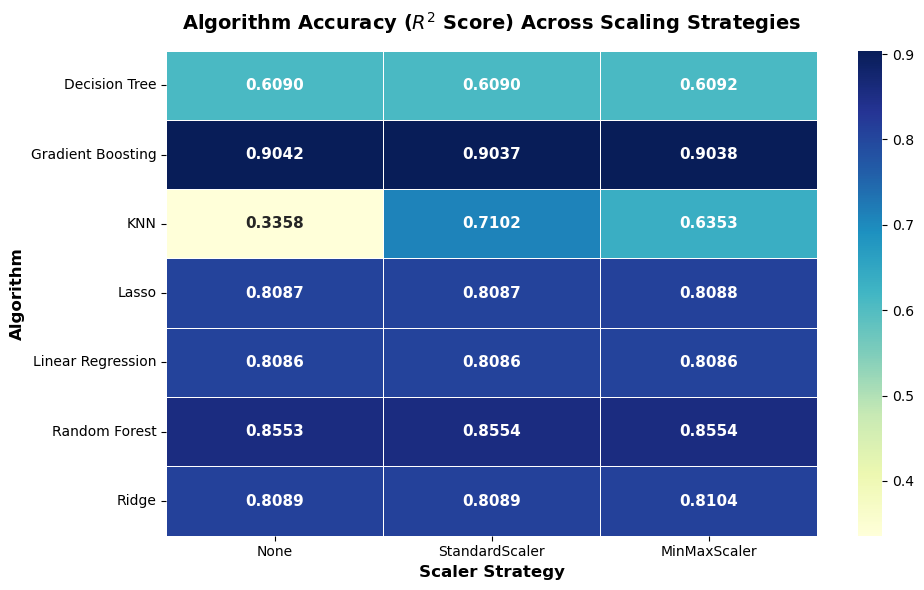

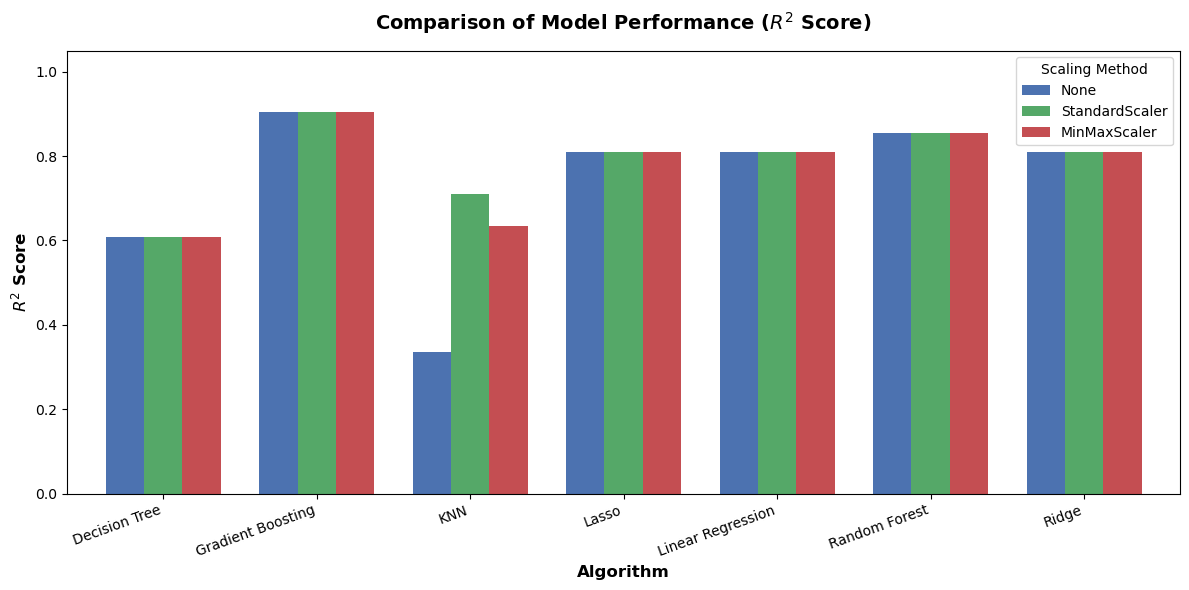

In [7]:
results_df = pd.DataFrame(results)
pivot_df = results_df.pivot(index="Algorithm", columns="Scaler", values="R2 Score")
pivot_df = pivot_df[['None', 'StandardScaler', 'MinMaxScaler']]
plt.figure(figsize=(10, 6))
sns.heatmap(
    pivot_df, 
    annot=True, 
    fmt=".4f", 
    cmap="YlGnBu", 
    linewidths=0.5, 
    cbar=True,
    annot_kws={"size": 11, "weight": "bold"}
)
plt.title("Algorithm Accuracy ($R^2$ Score) Across Scaling Strategies", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Scaler Strategy", fontsize=12, fontweight='bold')
plt.ylabel("Algorithm", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# VISUALIZATION 2: Grouped Bar Chart
# ==========================================
fig, ax = plt.subplots(figsize=(12, 6))
pivot_df.plot(
    kind='bar', 
    ax=ax, 
    width=0.75, 
    color=['#4c72b0', '#55a868', '#c44e52']
)
plt.title("Comparison of Model Performance ($R^2$ Score)", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("$R^2$ Score", fontsize=12, fontweight='bold')
plt.xlabel("Algorithm", fontsize=12, fontweight='bold')
plt.xticks(rotation=20, ha='right', fontsize=10)
plt.ylim(0, 1.05)
plt.legend(title="Scaling Method", frameon=True)
plt.tight_layout()
plt.show()

In [8]:
results = []
pipelines = {}

for scaler_name, scaler in scalers.items():
    num_transformer = scaler if scaler is not None else 'passthrough'
    
    preprocessor = ColumnTransformer([
        ('num', num_transformer, num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

    for model_name, model in models.items():
        key = f"{model_name} ({scaler_name})"
        
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('regressor', model)
        ])
        
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        
        r2 = r2_score(y_test, y_pred)
        rmse = root_mean_squared_error(y_test, y_pred)
        
        results.append({
            "Key": key,
            "Model": model_name,
            "Scaler": scaler_name,
            "R2 Score": r2,
            "RMSE": rmse
        })
        pipelines[key] = pipeline

In [9]:
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
best_key = results_df.iloc[0]['Key']
best_pipeline = pipelines[best_key]

# Prepare pivot table for visual heatmaps
pivot_df = results_df.pivot(index="Model", columns="Scaler", values="R2 Score")
pivot_df = pivot_df[['None', 'StandardScaler', 'MinMaxScaler']]
def generate_heatmap():
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.heatmap(
        pivot_df, 
        annot=True, 
        fmt=".4f", 
        cmap="YlGnBu", 
        linewidths=0.5, 
        ax=ax,
        annot_kws={"size": 10, "weight": "bold"}
    )
    ax.set_title("Algorithm Performance Across Scalers ($R^2$ Score)", fontweight='bold', pad=12)
    plt.tight_layout()
    return fig

def generate_scatter_plot():
    fig, ax = plt.subplots(figsize=(7, 4.5))
    y_pred = best_pipeline.predict(X_test)
    
    ax.scatter(y_test, y_pred, alpha=0.5, color='#2b5c8f')
    max_val = max(y_test.max(), y_pred.max())
    min_val = min(y_test.min(), y_pred.min())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Predictions')
    
    ax.set_title(f"Actual vs Predicted Prices ({best_key})", fontweight='bold')
    ax.set_xlabel("Actual Price ($)")
    ax.set_ylabel("Predicted Price ($)")
    ax.legend()
    plt.tight_layout()
    return fig

# ==========================================
# 3. PREDICTION FUNCTION FOR GRADIO
# ==========================================

def predict_house_price(*args):
    # Ensure they are standard lists before concatenation
    all_cols = list(num_cols) + list(cat_cols)
    
    input_data = {}
    for col, val in zip(all_cols, args):
        input_data[col] = [val]
    
    input_df = pd.DataFrame(input_data)
    
    # Feature engineering (if applicable)
    if {'total_rooms', 'households'}.issubset(input_df.columns):
        input_df['rooms_per_household'] = input_df['total_rooms'] / input_df['households']

    # Predict using the trained best pipeline
    prediction = best_pipeline.predict(input_df)[0]
    return f"${prediction:,.2f}"

# ==========================================
# 4. GRADIO WEB INTERFACE
# ==========================================

# Dynamically construct input widgets based on dataset columns
inputs = []
for col in num_cols:
    default_val = int(X[col].mean())
    inputs.append(gr.Number(label=col, value=round(default_val, 2)))

for col in cat_cols:
    choices = list(X[col].unique())
    inputs.append(gr.Dropdown(label=col, choices=choices, value=choices[0]))

# Define Web App Layout
with gr.Blocks(title="House Price Prediction Dashboard") as demo:
    gr.Markdown("# 🏡 House Price Prediction Web App")
    gr.Markdown(f"**Best Performing Model:** `{best_key}` (R² = {results_df.iloc[0]['R2 Score']:.4f})")
    
    with gr.Tab("Predict Price"):
        with gr.Row():
            with gr.Column():
                gr.Markdown("### Enter House Details")
                predict_btn = gr.Button("Calculate Estimated Price", variant="primary")
                # Group input fields
                for input_widget in inputs:
                    input_widget.render()
                    
            with gr.Column():
                gr.Markdown("### Prediction Result")
                output_text = gr.Textbox(label="Estimated House Price", interactive=False)
                
                gr.Markdown("### Actual vs Predicted Line")
                gr.Plot(value=generate_scatter_plot())
                
        predict_btn.click(fn=predict_house_price, inputs=inputs, outputs=output_text)
        
    with gr.Tab("Algorithm & Scaler Comparison"):
        gr.Markdown("### R² Score Heatmap (21 Model Combinations)")
        gr.Plot(value=generate_heatmap())
        
        gr.Markdown("### Complete Leaderboard")
        gr.Dataframe(value=results_df[["Key", "Model", "Scaler", "R2 Score", "RMSE"]])

# Launch local server
if __name__ == "__main__":
    demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [10]:
import joblib

# Save the winning pipeline (includes preprocessor + best algorithm)
model_filename = "best_house_price_model.pkl"
joblib.dump(best_pipeline, filename=model_filename)

print(f" Saved best model to {model_filename}")

 Saved best model to best_house_price_model.pkl


In [23]:

pip install scikit-learn==1.7.2

Note: you may need to restart the kernel to use updated packages.


In [11]:
import joblib

# Get the best scaler and model names
best_scaler_name = best_run["Scaler"]
best_model_name = best_run["Algorithm"]

# Recreate the scaler
if best_scaler_name == "None":
    num_transformer = "passthrough"
elif best_scaler_name == "StandardScaler":
    num_transformer = StandardScaler()
elif best_scaler_name == "MinMaxScaler":
    num_transformer = MinMaxScaler()

# Recreate the model
if best_model_name == "Linear Regression":
    best_model = LinearRegression()
elif best_model_name == "Ridge":
    best_model = Ridge()
elif best_model_name == "Lasso":
    best_model = Lasso(alpha=100.0, max_iter=10000, random_state=42)
elif best_model_name == "KNN":
    best_model = KNeighborsRegressor()
elif best_model_name == "Decision Tree":
    best_model = DecisionTreeRegressor(random_state=42)
elif best_model_name == "Random Forest":
    best_model = RandomForestRegressor(n_estimators=100, random_state=42)
elif best_model_name == "Gradient Boosting":
    best_model = GradientBoostingRegressor(random_state=42)

# Build the final pipeline
final_pipeline = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', num_transformer, num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])),
    ('regressor', best_model)
])

# Train on ALL data
final_pipeline.fit(X, y)

# Save the pipeline
joblib.dump(final_pipeline, "best_house_price_model.pkl")

print("✅ Model saved as best_house_price_model.pkl")

✅ Model saved as best_house_price_model.pkl
